<a href="https://colab.research.google.com/github/GHseyram/Ghana-energy-transition-investment-analytics/blob/main/notebooks/06_ghana_south_africa_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Commercial Rooftop Solar: Ghana and South Africa
## Comparative Evidence and Lessons for Ghana

Author: Seyram Amedede

### Research question
Which features of South Africa's commercial rooftop solar
market could inform solar investment and adoption in Ghana?

### Comparison areas
- Evidence of adoption and market growth
- Installation costs for comparable systems
- Customer tariffs and electricity reliability
- Financing arrangements
- Registration and grid-connection processes
- Installer standards and supply chains

### Method
Record each source, date, geographic scope and limitations.
Distinguish observed outcomes from estimates and supplier claims.

Compare costs only after checking system capacity, DC:AC ratio,
battery inclusion, taxes, installation scope and price date.

### Interpretation
South Africa's success will be assessed using measurable
outcomes rather than assumed. Differences between the countries
will guide which lessons may be transferable.

The Focal Energy price guide is a candidate source pending
verification. It is not a Ghana installation-cost estimate.

### Source SA01: Focal Energy cost guide

Title: What does commercial solar cost in South Africa?
URL:
https://www.focalenergy.co.za/knowledge/commercial-solar-cost-south-africa

Page updated: 1 October 2026
Accessed: 31 October 2026

Published budget indication:
100 kWp grid-tied commercial rooftop PV: ZAR 870,000,
equivalent to ZAR 8,700/kWp. VAT and batteries are excluded.

Evidence classification:
Supplier-published planning estimate, not an actual project
quotation or a representative national average.

Comparability limitations:
Site-specific extras are excluded. The page lists mounting
among installation components but also lists mounting-structure
type among exclusions; the exact allowance requires clarification.
The 100 kWp example does not specify inverter AC capacity.

Decision:
Retain as a South African supplier benchmark. Do not substitute
it for Ghana installation costs or convert to USD until a dated
exchange-rate source is documented.

In [1]:
import pandas as pd

sa_cost_benchmark = pd.DataFrame({
    "PV capacity (kWp)": [50, 100, 200, 500, 1000],
    "Indicative installation cost (ZAR)": [
        520000, 870000, 1570000, 3620000, 6700000
    ]
})

sa_cost_benchmark["Cost (ZAR/kWp)"] = (
    sa_cost_benchmark["Indicative installation cost (ZAR)"]
    / sa_cost_benchmark["PV capacity (kWp)"]
)

sa_cost_benchmark["Source"] = "SA01"
sa_cost_benchmark["Price date"] = "2026-10-01"
sa_cost_benchmark["Scope"] = "Grid-tied; excludes VAT and batteries"

sa_cost_benchmark


,PV capacity (kWp),Indicative installation cost (ZAR),Cost (ZAR/kWp),Source,Price date,Scope
0,50,520000,10400.0,SA01,2026-10-01,Grid-tied; excludes VAT and batteries
1,100,870000,8700.0,SA01,2026-10-01,Grid-tied; excludes VAT and batteries
2,200,1570000,7850.0,SA01,2026-10-01,Grid-tied; excludes VAT and batteries
3,500,3620000,7240.0,SA01,2026-10-01,Grid-tied; excludes VAT and batteries
4,1000,6700000,6700.0,SA01,2026-10-01,Grid-tied; excludes VAT and batteries


### How market success will be assessed

A supplier's installation prices alone cannot establish market
success. The comparison will seek evidence of:

1. Adoption: growth in commercial rooftop installations or capacity.
2. Customer outcomes: measured generation, savings and reliability.
3. Investment access: financing availability, terms and eligibility.
4. Implementation: connection timelines and administrative requirements.

For each indicator, record the year, customer segment, definition
and source. National solar totals must not be presented as
commercial rooftop capacity unless that segment is identified.

The analysis will distinguish evidence of market growth from
evidence explaining its causes. Policy recommendations for Ghana
will account for differences in tariffs, financing, institutions
and customer demand.

## South Africa: Rooftop Solar PV Market Adoption

This section examines the growth of embedded rooftop solar
photovoltaic capacity in South Africa between 2021 and
the first half of 2025.

The dataset is obtained from the CSIR Energy Research
Centre, Utility Statistics Report 2025.

The analysis will:
1. Examine annual rooftop PV capacity growth.
2. Calculate percentage changes.
3. Visualize market expansion.
4. Identify lessons for Ghana's commercial and industrial
   rooftop solar investment market.

Note: The 2025 observation represents the first half
of the year and is not directly comparable to full-year
observations without accounting for the time difference.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

south_africa_solar = pd.DataFrame({
    "Period": ["2021", "2022", "2023", "2024", "2025 H1"],
    "Capacity_MW": [1350, 2586, 5204, 6165, 6800]
})

south_africa_solar["Growth_Percent"] = (
    south_africa_solar["Capacity_MW"].pct_change() * 100
).round(2)

display(south_africa_solar)

,Period,Capacity_MW,Growth_Percent
0,2021,1350,NaN
1,2022,2586,91.56
2,2023,5204,101.24
3,2024,6165,18.47
4,2025 H1,6800,10.30


### South African rooftop PV adoption: interpretation

Estimated embedded rooftop PV capacity increased from approximately
1,350 MW in 2021 to 6,800 MW by June 2025—about fivefold.

Growth between the reported observations was 91.56% in 2022,
101.24% in 2023 and 18.47% in 2024. Capacity increased another
10.30% between December 2024 and June 2025; this is a six-month
change, not an annual growth rate.

Source: CSIR, Utility-scale power generation statistics,
2025 H1 report, drawing on Eskom rooftop PV estimates.
The 2021 figure is a triangulated estimate using OECD and
GreenCape evidence, so the series has a methodological limitation.

These figures indicate substantial aggregate rooftop PV expansion.
They do not isolate commercial installations, measure customer
profitability or establish what caused adoption.

The first growth value is unavailable because the table contains
no preceding observation.

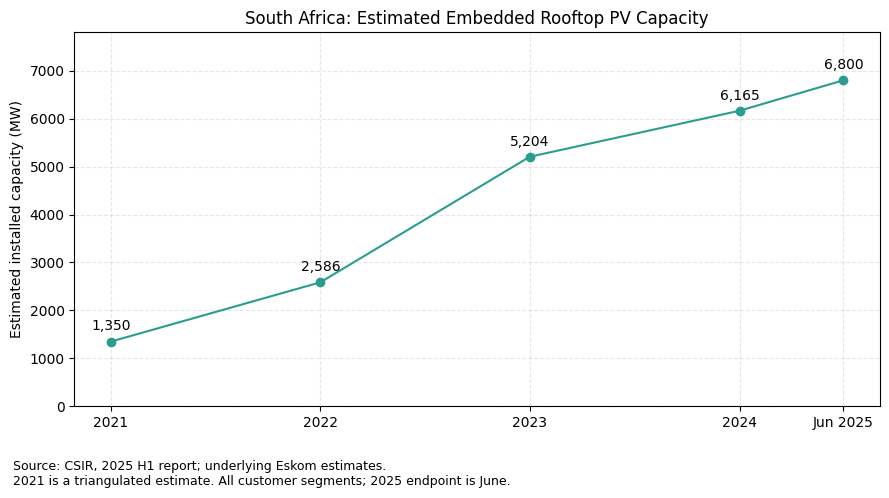

In [3]:
import matplotlib.pyplot as plt

# Reported capacity observations; 2025 covers June only
dates = pd.to_datetime([
    "2021-12-31", "2022-12-31", "2023-12-31",
    "2024-12-31", "2025-06-30"
])
capacity_mw = [1350, 2586, 5204, 6165, 6800]
labels = ["2021", "2022", "2023", "2024", "Jun 2025"]

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(dates, capacity_mw, marker="o", color="#2A9D8F")

for date, capacity in zip(dates, capacity_mw):
    ax.annotate(
        f"{capacity:,}",
        (date, capacity),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center"
    )

ax.set_xticks(dates)
ax.set_xticklabels(labels)
ax.set_ylabel("Estimated installed capacity (MW)")
ax.set_title("South Africa: Estimated Embedded Rooftop PV Capacity")
ax.set_ylim(0, 7800)
ax.grid(True, linestyle="--", alpha=0.3)

fig.text(
    0.02, 0.02,
    "Source: CSIR, 2025 H1 report; underlying Eskom estimates.\n"
    "2021 is a triangulated estimate. All customer segments; "
    "2025 endpoint is June.",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.10, 1, 1])
plt.show()

### Financing evidence: Standard Bank Business Solar Financing

Source:
https://www.standardbank.co.za/southafrica/business/products-and-services/borrow-for-your-needs/business-loans/business%E2%80%93solar%E2%80%93financing

Accessed: 31 October 2026
Evidence type: Lender-published product information.

Advertised features:
- Minimum loan amount: ZAR 10,000.
- Repayment term: up to 60 months.
- Covers grid-tied, hybrid and off-grid solar systems.
- Personalised interest pricing; the page advertises prime + 2.5%.
- Approval depends on credit and compliance checks.
- New-to-bank applicants require at least two years of trading history.

Interpretation:
A dedicated lending product offers eligible businesses a way to
spread upfront investment over time. Interest and fees add costs,
and debt repayments must be assessed against project cash flows.

Limitations:
The page does not establish approval rates, lending volumes,
borrower savings or whether financing caused rooftop PV adoption.

Question for Ghana:
Are comparable products available, and which businesses qualify?
Investigate loan terms, collateral, fees and supplier requirements
before recommending a similar approach.

### Ghana financing evidence: Stanbic Bank Ghana

Source:
https://www.stanbicbank.com.gh/gh/business/products-and-services/borrow-for-your-needs/solar-and-electric-vehicle-finance

Accessed: 31 October 2026
Evidence type: Lender-published product information.

Advertised solar financing features:
- Up to 100% of system cost, subject to terms.
- Solar repayment tenor: 7–10 years.
- Covers panels, batteries and inverters.
- Financed equipment serves as collateral/security.
- Applicants require stable, verifiable income or cash flows,
  repayment capacity and compliance with bank credit requirements.
- Systems must come from accredited EPCs and approved suppliers.

Comparison:
This Ghana offering advertises a longer solar repayment period
than the up-to-60-month Standard Bank South Africa product reviewed.
These two products do not represent either country's entire market.

Limitations:
The Ghana page does not specify a numerical interest rate or
complete fee schedule. Neither product page establishes approval
rates, lending volumes or realised customer outcomes.

Implication:
Investigate affordability, eligibility and actual uptake before
concluding that financing availability explains adoption differences.

In [4]:
financing_comparison = pd.DataFrame([
    {
        "Country": "South Africa",
        "Lender": "Standard Bank",
        "Product": "Business Solar Financing",
        "Advertised solar repayment term": "Up to 5 years",
        "Maximum financed share": "Not established from reviewed page",
        "Interest pricing": "Personalised; advertises prime + 2.5%",
        "Eligibility": "Credit and compliance checks; new clients need ≥2 years trading",
        "Evidence of uptake": "Not established"
    },
    {
        "Country": "Ghana",
        "Lender": "Stanbic Bank Ghana",
        "Product": "Solar and Electric Vehicle Finance",
        "Advertised solar repayment term": "7–10 years",
        "Maximum financed share": "Up to 100%, subject to terms",
        "Interest pricing": "Numerical rate not stated on reviewed page",
        "Eligibility": "Verifiable cash flows; credit approval; approved suppliers",
        "Evidence of uptake": "Not established"
    }
])

financing_comparison

,Country,Lender,Product,Advertised solar repayment term,Maximum financed share,Interest pricing,Eligibility,Evidence of uptake
0,South Africa,Standard Bank,Business Solar Financing,Up to 5 years,Not established from reviewed page,Personalised; advertises prime + 2.5%,Credit and compliance checks; new clients need...,Not established
1,Ghana,Stanbic Bank Ghana,Solar and Electric Vehicle Finance,7–10 years,"Up to 100%, subject to terms",Numerical rate not stated on reviewed page,Verifiable cash flows; credit approval; approv...,Not established


### Financing comparison: preliminary finding

Dedicated business solar financing is advertised in both countries.
The reviewed Ghana product offers a longer repayment period, but
this alone does not demonstrate greater affordability or access.

A meaningful comparison still requires:
- Interest rates, fees and loan currency.
- Deposit and security requirements.
- Repayment schedules and total borrowing costs.
- Approval rates, disbursements and customer uptake.

These two lender products are examples, not national market averages.
Their availability does not establish that financing caused the
observed difference in rooftop solar adoption.

Notebook 05 remains an unlevered project analysis: loan proceeds,
interest and debt repayments are not included in its cash flows.
Assessing borrower affordability would require a separate financing
schedule with documented loan terms.